In [19]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

In [2]:
df = pd.read_csv('networkTraffic.csv', na_values='?')
df.head()

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat
0,1,0.000011,udp,NaN,INT,2,0,496,0,90909.0902,...,1,1,2,0,0,0,1,2,0,0
1,2,0.000008,udp,NaN,INT,2,0,1762,0,125000.0003,...,1,1,2,0,0,0,1,2,0,0
2,3,0.000005,udp,NaN,INT,2,0,1068,0,200000.0051,...,1,1,3,0,0,0,1,3,0,0
3,4,0.000006,udp,NaN,INT,2,0,900,0,166666.6608,...,2,1,3,0,0,0,2,3,0,0
4,5,0.000010,udp,NaN,INT,2,0,2126,0,100000.0025,...,2,1,3,0,0,0,2,3,0,0


In [3]:
X = df.drop(columns=["attack_cat", "id"])
y = df["attack_cat"]
print(y)

0         0
1         0
2         0
3         0
4         0
         ..
257668    9
257669    8
257670    9
257671    9
257672    9
Name: attack_cat, Length: 257673, dtype: int64


In [4]:
headings_cont = ['Feature', 'Count', '% Miss.', 'Range', 'Card.', 'Min.', '1st Qrt.', 'Mean', 'Median', '3rd Qrt.', 'Max.', 'Std. Dev']
df_cont = X.select_dtypes(include=['number'])

In [5]:
DQR_cont = pd.DataFrame(columns=headings_cont)

DQR_cont["Feature"] = df_cont.columns
DQR_cont["Count"] = df_cont.shape[0]
DQR_cont["% Miss."] = df_cont.isnull().sum().values / y.shape[0] * 100
DQR_cont["Range"] = df_cont.max().values - df_cont.min().values
DQR_cont["Card."] = df_cont.nunique().values
DQR_cont["Min."] = df_cont.min().values
DQR_cont["1st Qrt."] = df_cont.quantile(0.25).values
DQR_cont["Mean"] = df_cont.mean().values
DQR_cont["Median"] = df_cont.median().values
DQR_cont["3rd Qrt."] = df_cont.quantile(0.75).values
DQR_cont["Max."] = df_cont.max().values
DQR_cont["Std. Dev"] = df_cont.std().values

DQR_cont.to_csv("DQR_target.csv", index=False, header=False)
DQR_cont

,Feature,Count,% Miss.,Range,Card.,Min.,1st Qrt.,Mean,Median,3rd Qrt.,Max.,Std. Dev
0,dur,257673,0.0,5.999999e+01,109945,0.0,0.000008,1.246715e+00,0.004285,6.857770e-01,5.999999e+01,5.974305e+00
1,spkts,257673,0.0,1.064500e+04,646,1.0,2.000000,1.977714e+01,4.000000,1.200000e+01,1.064600e+04,1.359472e+02
2,dpkts,257673,0.0,1.101800e+04,627,0.0,0.000000,1.851470e+01,2.000000,1.000000e+01,1.101800e+04,1.119860e+02
3,sbytes,257673,0.0,1.435575e+07,9382,24.0,114.000000,8.572952e+03,528.000000,1.362000e+03,1.435577e+07,1.737739e+05
4,dbytes,257673,0.0,1.465753e+07,8653,0.0,0.000000,1.438729e+04,178.000000,1.064000e+03,1.465753e+07,1.461993e+05
5,rate,257673,0.0,1.000000e+06,115763,0.0,30.789277,9.125391e+04,2955.664893,1.250000e+05,1.000000e+06,1.603446e+05
6,sttl,257673,0.0,2.550000e+02,13,0.0,62.000000,1.800009e+02,254.000000,2.540000e+02,2.550000e+02,1.024883e+02
7,dttl,257673,0.0,2.540000e+02,9,0.0,0.000000,8.475496e+01,29.000000,2.520000e+02,2.540000e+02,1.127621e+02
8,sload,257673,0.0,5.988000e+09,121356,0.0,12318.004880,7.060869e+07,743942.312500,8.000000e+07,5.988000e+09,1.857313e+08
9,dload,257673,0.0,2.242273e+07,116380,0.0,0.000000,6.582143e+05,1747.441284,2.210538e+04,2.242273e+07,2.412372e+06


In [6]:
headings_cat = ['Feature', 'Count', '% Miss.', 'Card.', 'Mode', 'Mode Freq.', 'Mode %', '2nd Mode', '2nd Mode Freq.', '2nd Mode %']
df_cat = X.select_dtypes(include=['object'])

DQR_cat = pd.DataFrame(columns=headings_cat)
DQR_cat["Feature"] = df_cat.columns
DQR_cat["Count"] = df_cat.shape[0]
DQR_cat["% Miss."] = df_cat.isnull().sum().values / df_cat.shape[0] * 100
DQR_cat["Card."] = df_cat.nunique().values
DQR_cat["Mode"] = df_cat.mode().iloc[0].values
DQR_cat["Mode Freq."] = df_cat.apply(lambda col: col.value_counts().max()).values
DQR_cat["Mode %"] = DQR_cat["Mode Freq."] / df_cat.shape[0] * 100
DQR_cat["2nd Mode"] = df_cat.apply(lambda col: col.value_counts().index[1]).values
DQR_cat["2nd Mode Freq."] =  df_cat.apply(lambda col: col.value_counts().iloc[1]).values
DQR_cat["2nd Mode %"] = DQR_cat["2nd Mode Freq."] / df_cat.shape[0] * 100

DQR_cat.to_csv("DQR_cat.csv", index=False, header=False)
DQR_cat

,Feature,Count,% Miss.,Card.,Mode,Mode Freq.,Mode %,2nd Mode,2nd Mode Freq.,2nd Mode %
0,proto,257673,0.000000,133,tcp,123041,47.750831,udp,92701,35.976218
1,service,257673,54.845094,12,dns,68661,26.646564,http,27011,10.482666
2,state,257673,0.000000,11,FIN,117164,45.470034,INT,116438,45.188281


In [7]:
X["service"] = X["service"].fillna("unknown")

In [8]:
encoder = LabelEncoder()
y = encoder.fit_transform(y)

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0,stratify=y)

In [10]:
top_protos = X_train["proto"].value_counts()
keep = top_protos[top_protos >= 500].index
X_train["proto"] = X_train["proto"].where(X_train["proto"].isin(keep), "other")
X_test["proto"] = X_test["proto"].where(X_test["proto"].isin(keep), "other")

In [11]:
categorical_cols = ["proto", "service", "state"]

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

encoder.fit(X_train[categorical_cols])

encoded_train = encoder.transform(X_train[categorical_cols])
encoded_train_df = pd.DataFrame(
    encoded_train,
    columns=encoder.get_feature_names_out(categorical_cols),
    index=X_train.index
)

encoded_test = encoder.transform(X_test[categorical_cols])
encoded_test_df = pd.DataFrame(
    encoded_test,
    columns=encoder.get_feature_names_out(categorical_cols),
    index=X_test.index
)

X_train = X_train.drop(columns=categorical_cols)
X_train = pd.concat([X_train, encoded_train_df], axis=1)

X_test = X_test.drop(columns=categorical_cols)
X_test = pd.concat([X_test, encoded_test_df], axis=1)

In [12]:
params = {
    "n_estimators": [50, 100, 200],
    "max_depth": [10, 20, None],
    "class_weight": [None, "balanced"]
}

forest_search = GridSearchCV(
    RandomForestClassifier(random_state=0, n_jobs=-1),
    param_grid=params,
    scoring="f1_macro",
    cv=3,
    n_jobs=-1
)

forest_search.fit(X_train, y_train)

print("Best parameters:")
print(forest_search.best_params_)

print("\nBest CV Macro F1:")
print(forest_search.best_score_)

Best parameters:
{'class_weight': 'balanced', 'max_depth': 20, 'n_estimators': 200}

Best CV Macro F1:
0.573674388069523


In [15]:
results = pd.DataFrame(forest_search.cv_results_)

tuning_results = results[
    [
        'param_n_estimators',
        'param_max_depth',
        'param_class_weight',
        'mean_test_score',
        'std_test_score',
        'rank_test_score'
    ]
].copy()

tuning_results.columns = [
    'n_estimators',
    'max_depth',
    'class_weight',
    'mean_macro_f1',
    'std_macro_f1',
    'rank'
]

tuning_results = tuning_results.sort_values(
    'rank'
).reset_index(drop=True)

print(tuning_results.to_string(index=False))

print("\nBest parameters:")
print(forest_search.best_params_)

print("\nBest cross-validation macro F1:")
print(forest_search.best_score_)

 n_estimators max_depth class_weight  mean_macro_f1  std_macro_f1  rank
          200        20     balanced       0.573674      0.008892     1
          100        20     balanced       0.572946      0.008573     2
           50        20     balanced       0.572640      0.007429     3
          200      None     balanced       0.564776      0.004272     4
          100      None     balanced       0.560378      0.002669     5
          100      None         None       0.560102      0.009548     6
           50      None     balanced       0.559892      0.002945     7
           50      None         None       0.558413      0.008926     8
          200      None         None       0.557545      0.008579     9
          200        20         None       0.545513      0.011879    10
          100        20         None       0.545302      0.011688    11
           50        20         None       0.544551      0.010538    12
          200        10     balanced       0.497304      0.00323

In [16]:
final_forest = forest_search.best_estimator_

y_pred_forest = final_forest.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_forest))
print("Macro Precision:", precision_score(y_test, y_pred_forest, average="macro"))
print("Macro Recall:", recall_score(y_test, y_pred_forest, average="macro"))
print("Macro F1:", f1_score(y_test, y_pred_forest, average="macro"))

print(classification_report(y_test, y_pred_forest))

Accuracy: 0.779761327253323
Macro Precision: 0.5923512755011178
Macro Recall: 0.6428356889297201
Macro F1: 0.597591620683046
              precision    recall  f1-score   support

           0       0.97      0.81      0.89     18600
           1       0.88      0.83      0.85      2798
           2       0.04      0.15      0.07       466
           3       0.35      0.58      0.43      3271
           4       0.86      0.56      0.68      8905
           5       0.08      0.19      0.12       535
           6       0.55      0.80      0.65      4849
           7       0.73      0.69      0.71        35
           8       0.46      0.84      0.60       302
           9       1.00      0.98      0.99     11774

    accuracy                           0.78     51535
   macro avg       0.59      0.64      0.60     51535
weighted avg       0.85      0.78      0.80     51535



In [17]:
print("\nEffect of number of trees:")
print(
    tuning_results
    .groupby('n_estimators')['mean_macro_f1']
    .max()
)

print("\nEffect of maximum depth:")
print(
    tuning_results
    .groupby('max_depth')['mean_macro_f1']
    .max()
)

print("\nEffect of class weighting:")
print(
    tuning_results
    .groupby('class_weight')['mean_macro_f1']
    .max()
)


Effect of number of trees:
n_estimators
50     0.572640
100    0.572946
200    0.573674
Name: mean_macro_f1, dtype: float64

Effect of maximum depth:
max_depth
10    0.497304
20    0.573674
Name: mean_macro_f1, dtype: float64

Effect of class weighting:
class_weight
balanced    0.573674
Name: mean_macro_f1, dtype: float64


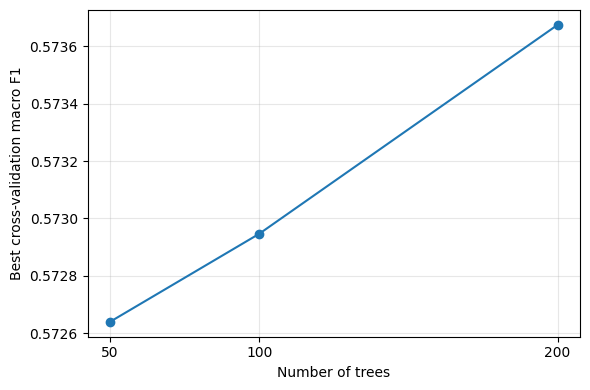

In [20]:
tree_results = (
    tuning_results
    .groupby('n_estimators')['mean_macro_f1']
    .max()
)

plt.figure(figsize=(6, 4))
plt.plot(
    tree_results.index,
    tree_results.values,
    marker='o'
)

plt.xlabel('Number of trees')
plt.ylabel('Best cross-validation macro F1')
plt.xticks(tree_results.index)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('rf_trees_vs_f1.png', dpi=300, bbox_inches='tight')
plt.show()

In [21]:
tuning_results['class_weight'] = (
    tuning_results['class_weight'].astype(str)
)

print(
    tuning_results
    .groupby('class_weight')['mean_macro_f1']
    .max()
)

class_weight
None        0.560102
balanced    0.573674
Name: mean_macro_f1, dtype: float64
